# Neural Networks

In [11]:
%pip install numpy pandas matplotlib torch ucimlrepo

### Recollecting Logistic Regression

Let's start off by recollecting **Logistic Regression**:

$$z = Wx + b$$

$$P(y = 1 \mid x) = \text{sigmoid}(z)$$

Let us look at how this works out in classifying a simple **XOR** function:

| $x_1$ | $x_2$ | $y$ |
| :---: | :---: | :---: |
| 0 | 0 | 0 |
| 1 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 1 | 0 |

Observe the decision boundary. Can it learn the **XOR** pattern ?

In [12]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

y = np.array([0, 1, 1, 0])
y = y.reshape(-1, 1)

Epoch    0 | Loss: 0.6962
Epoch  200 | Loss: 0.6933
Epoch  400 | Loss: 0.6932
Epoch  600 | Loss: 0.6931
Epoch  800 | Loss: 0.6931

Weights:
 [[0.00133341]
 [0.00073168]]
Bias: -0.0012247438663068265
Predictions: [0 1 0 1]
Actual:      [0 1 1 0]


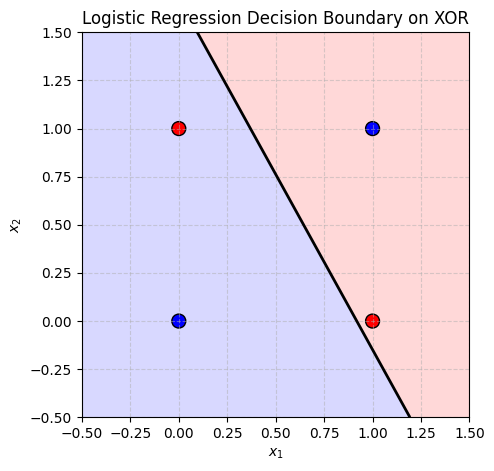

In [13]:
W = np.random.randn(2, 1) * 0.5
b = 0.0

def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# 3. Training loop (Gradient Descent)
lr = 0.1
epochs = 1000
for epoch in range(epochs):
    # Forward pass
    z = X @ W + b
    y_hat = sigmoid(z)

    # Binary cross-entropy loss
    loss = -np.mean(y * np.log(y_hat + 1e-8) + (1 - y) * np.log(1 - y_hat + 1e-8))

    # Gradient Descent
    dz = y_hat - y
    dW = (X.T @ dz) / len(X)
    db = np.mean(dz)

    # Parameter update
    W -= lr * dW
    b -= lr * db
    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | Loss: {loss:.4f}")

# 4. Predictions
preds = (sigmoid(X @ W + b) >= 0.5).astype(int)
print("\nWeights:\n", W)
print("Bias:", b)
print("Predictions:", preds.ravel())
print("Actual:     ", y.ravel().astype(int))

# 5. Plot the decision boundary
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = sigmoid(grid @ W + b).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], alpha=0.3, cmap="bwr")
plt.contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="bwr", edgecolors="k", s=100)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Logistic Regression Decision Boundary on XOR")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Stacking Logistic Regressions

Now let's try stacking logistic regressions over each other, giving the model more expressive power to learn some features:

$$z_1 = W_1 x + b_1 \quad \text{where } W_1 \text{ is } 2 \times 4 \text{ and } b_1 \text{ is } 1 \times 4$$

$$z = W_2 z_1 + b_2 \quad \text{where } W_2 \text{ is } 4 \times 1 \text{ and } b_2 \text{ is } 4 \times 1$$

$$P(y = 1 \mid x) = \text{sigmoid}(z)$$

Now again, observe the decision boundary. Is it able to learn the pattern?

Epoch    0 | Loss: 0.7192
Epoch  400 | Loss: 0.6932
Epoch  800 | Loss: 0.6931
Epoch 1200 | Loss: 0.6931
Epoch 1600 | Loss: 0.6931

Predictions: [1 1 0 0]
Actual:      [0 1 1 0]


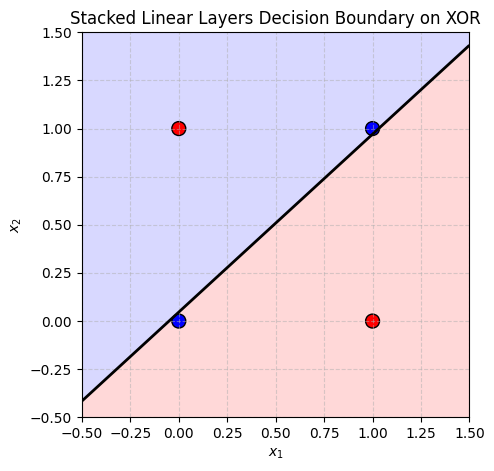

In [14]:
W1 = np.random.randn(2, 4) * 0.5
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.5
b2 = np.zeros((1, 1))
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
# 3. Training loop (Gradient Descent)
lr = 0.1
epochs = 2000
for epoch in range(epochs):
    # Forward pass
    z1 = X @ W1 + b1          # (4, 4)
    z = z1 @ W2 + b2          # (4, 1)
    y_hat = sigmoid(z)        # (4, 1)
    # Binary cross-entropy loss
    loss = -np.mean(y * np.log(y_hat + 1e-8) + (1 - y) * np.log(1 - y_hat + 1e-8))
    # Backward pass (gradients)
    dz = y_hat - y                              # (4, 1)
    dW2 = (z1.T @ dz) / len(X)                  # (4, 1)
    db2 = np.mean(dz, axis=0, keepdims=True)    # (1, 1)
    dz1 = dz @ W2.T                             # (4, 4)
    dW1 = (X.T @ dz1) / len(X)                  # (2, 4)
    db1 = np.mean(dz1, axis=0, keepdims=True)   # (1, 4)
    # Parameter update
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1
    if epoch % 400 == 0:
        print(f"Epoch {epoch:4d} | Loss: {loss:.4f}")
# 4. Predictions
z1_pred = X @ W1 + b1
preds = (sigmoid(z1_pred @ W2 + b2) >= 0.5).astype(int)
print("\nPredictions:", preds.ravel())
print("Actual:     ", y.ravel().astype(int))
# 5. Plot the decision boundary
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = sigmoid((grid @ W1 + b1) @ W2 + b2).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], alpha=0.3, cmap="bwr")
plt.contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="bwr", edgecolors="k", s=100)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Stacked Linear Layers Decision Boundary on XOR")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Adding Non-Linearity

Notice that logistic regression can only learn a linear decision boundary in the end. Hence, it fails to learn this **XOR** pattern.

**Solution:** Let's add some non-linearity in between these stacks.

Now let's try stacking logistic regressions over each other, giving the model more expressive power to learn some features:

$$z_1 = \text{sigmoid}(W_1 x + b_1) \quad \text{where } W_1 \text{ is } 2 \times 4 \text{ and } b_1 \text{ is } 1 \times 4$$

$$z = W_2 z_1 + b_2 \quad \text{where } W_2 \text{ is } 4 \times 1 \text{ and } b_2 \text{ is } 4 \times 1$$

$$P(y = 1 \mid x) = \text{sigmoid}(z)$$

Now again, observe the decision boundary. Is it able to learn the pattern?

Epoch    0 | Loss: 0.7349
Epoch 1000 | Loss: 0.0121
Epoch 2000 | Loss: 0.0040
Epoch 3000 | Loss: 0.0022
Epoch 4000 | Loss: 0.0015

Predictions: [0 1 1 0]
Actual:      [0 1 1 0]


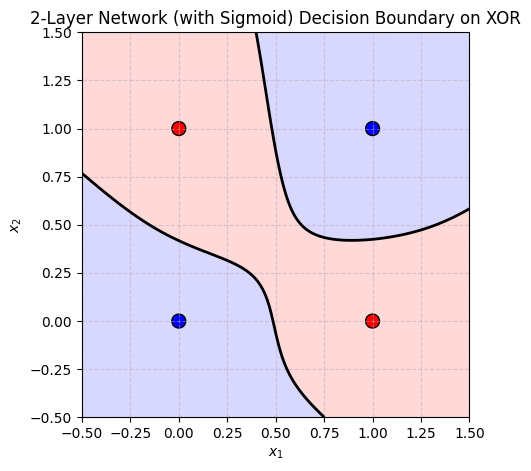

In [15]:
W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
# 3. Training loop (Gradient Descent)
lr = 1.0
epochs = 5000
for epoch in range(epochs):
    # Forward pass
    z1 = sigmoid(X @ W1 + b1)   # (4, 4)
    z = z1 @ W2 + b2            # (4, 1)
    y_hat = sigmoid(z)          # (4, 1)
    # Binary cross-entropy loss
    loss = -np.mean(y * np.log(y_hat + 1e-8) + (1 - y) * np.log(1 - y_hat + 1e-8))
    # Backward pass (gradients)
    dz = y_hat - y                              # (4, 1)
    dW2 = (z1.T @ dz) / len(X)                  # (4, 1)
    db2 = np.mean(dz, axis=0, keepdims=True)    # (1, 1)
    dz1 = dz @ W2.T                             # (4, 4)
    d_pre = dz1 * z1 * (1 - z1)                 # sigmoid derivative
    dW1 = (X.T @ d_pre) / len(X)                # (2, 4)
    db1 = np.mean(d_pre, axis=0, keepdims=True) # (1, 4)
    # Parameter update
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1
    if epoch % 1000 == 0:
        print(f"Epoch {epoch:4d} | Loss: {loss:.4f}")
# 4. Predictions
z1_pred = sigmoid(X @ W1 + b1)
preds = (sigmoid(z1_pred @ W2 + b2) >= 0.5).astype(int)
print("\nPredictions:", preds.ravel())
print("Actual:     ", y.ravel().astype(int))
# 5. Plot the decision boundary
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = sigmoid(sigmoid(grid @ W1 + b1) @ W2 + b2).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], alpha=0.3, cmap="bwr")
plt.contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="bwr", edgecolors="k", s=100)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("2-Layer Network (with Sigmoid) Decision Boundary on XOR")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Backpropagation

What we built above is a simple **Multi-Layer Perceptron (MLP)**, also called a **Neural Network**.

Notice that in the previous code we **worked out the derivatives by hand** for the gradient-descent weight updates. That is fine for a tiny network like this, but for large networks it would be impossible.

We need a method that is:
1. **General**: it works for any number of layers and neurons.
2. **Efficient**: it reuses work instead of recomputing it.

That method is **Backpropagation**. It is the **chain rule of calculus**, applied layer by layer from the output back to the input, storing intermediate results along the way.

### The tool: the chain rule

If a quantity $F$ depends on $w$ only through a chain $w \rightarrow z \rightarrow y \rightarrow F$, then

$$\frac{\partial F}{\partial w} = \frac{\partial F}{\partial y} \cdot \frac{\partial y}{\partial z} \cdot \frac{\partial z}{\partial w}$$

If $w$ affects $F$ through **several paths**, we **add up** the contributions from every path:

$$\frac{\partial F}{\partial w} = \sum_{\text{paths } i} \frac{\partial F}{\partial u_i} \cdot \frac{\partial u_i}{\partial w}$$

In a neural network, every weight affects the loss through a chain of the form

$$w^{l}_{k\to j} \;\longrightarrow\; z^{l}_{j} \;\longrightarrow\; a^{l}_{j} \;\longrightarrow\; \text{(later layers)} \;\longrightarrow\; C$$

### Notation

We use the following notation for a network with layers $l = 1, 2, \dots, L$ (layer $L$ is the output layer):

| Symbol | Meaning |
|---|---|
| $w^{l}_{k \to j}$ | weight on the edge **from** neuron $k$ in layer $l-1$ **to** neuron $j$ in layer $l$ |
| $b^{l}_{j}$ | bias of neuron $j$ in layer $l$ |
| $z^{l}_{j}$ | weighted sum of inputs plus bias for neuron $j$ in layer $l$ (*before* activation) |
| $a^{l}_{j}$ | output of neuron $j$ in layer $l$ (*after* activation) |
| $\sigma(\cdot)$ | activation function (sigmoid, ReLU, …) and $\sigma'(\cdot)$ its derivative |
| $C$ | cost / loss function |
| $\hat{y}_j = a^{L}_{j}$ | the network's prediction (output of the last layer) |
| $\eta$ | learning rate |

        layer l-1          layer l
        neuron k  ──── w^l_{k→j} ────►  neuron j
         (a_k^{l-1})                    z_j^l → σ → a_j^l

> **Link to `Wx + b`:** if we collect all the weights of layer $l$ into a matrix $W^l$ whose entry in row $j$, column $k$ is $w^l_{k\to j}$, then a whole layer is just $\mathbf{z}^l = W^l \mathbf{a}^{l-1} + \mathbf{b}^l$, the same expression we started with.

### Training a neural network: the four steps

**1. Forward pass:** pass the input through every layer, $l = 1, \dots, L$ (with $a^{0} = x$):

$$z^{l}_{j} = \sum_{k} w^{l}_{k \to j}\, a^{l-1}_{k} + b^{l}_{j}, \qquad a^{l}_{j} = \sigma(z^{l}_{j})$$

The output of the last layer is the prediction: $\hat{y} = a^{L}$.

**2. Compute the loss:** measure how far the prediction is from the true label, e.g.

$$C = \frac{1}{2}\sum_{j} (\hat{y}_j - y_j)^2$$

**3. Backpropagation:** use the chain rule to find how much each weight and bias contributed to the loss, i.e. compute

$$\frac{\partial C}{\partial w^{l}_{k\to j}} \quad \text{and} \quad \frac{\partial C}{\partial b^{l}_{j}} \qquad \text{for every layer } l$$

Start from the output layer and move **backwards**: each layer's gradients are built from the layer after it, so nothing is recomputed. A single backward pass gives the gradient for every parameter in the network.

**4. Gradient descent:** step each parameter against its gradient, with learning rate $\eta$:

$$w^{l}_{k\to j} \leftarrow w^{l}_{k\to j} - \eta\,\frac{\partial C}{\partial w^{l}_{k\to j}}, \qquad b^{l}_{j} \leftarrow b^{l}_{j} - \eta\,\frac{\partial C}{\partial b^{l}_{j}}$$

Repeat steps 1–4 until the loss stops improving.

## Creating a neural network in pytorch

We will trying out Mushroom dataset for classification using neural network. The UCI Mushroom dataset describes 8,124 hypothetical gilled mushrooms from 23 species of the Agaricus and Lepiota families. The task is binary classification: edible (4,208, 51.8%) vs poisonous (3,916, 48.2%). Mushrooms of unknown edibility, or not recommended, are counted as poisonous.

In [16]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from ucimlrepo import fetch_ucirepo

# 1. Load
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features   # 22 categorical columns
y = mushroom.data.targets    # 'e' (edible) / 'p' (poisonous)

# 2. Missing values: stalk-root ('?' in the raw file) -> its own category
X = X.fillna("missing").replace("?", "missing")

# 3. Drop constant columns (veil-type has a single value)
X = X.loc[:, X.nunique() > 1]

# 4. Labels: edible = 0, poisonous = 1
y = y.iloc[:, 0].map({"e": 0, "p": 1}).values

# 5. Split 70 / 15 / 15, stratified
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

# 6. One-hot encode (fit on train only)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train = encoder.fit_transform(X_train)
X_val = encoder.transform(X_val)
X_test = encoder.transform(X_test)
print("Features after one-hot:", X_train.shape[1])

# 7. Tensors and DataLoaders
def to_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, shuffle=True)
val_loader = to_loader(X_val, y_val, shuffle=False)
test_loader = to_loader(X_test, y_test, shuffle=False)

print(f"Train {len(X_train)}, Val {len(X_val)}, Test {len(X_test)}")

Features after one-hot: 116
Train 5686, Val 1219, Test 1219


In [17]:
import torch
import torch.nn as nn

class PoisonousMushroomDetector(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )
        self.sig = nn.Sigmoid()

    def forward(self, x):
        logit = self.mlp(x).squeeze(1)
        prob = self.sig(logit)
        return prob                      # probability of poisonous, shape [batch]

In [ ]:
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PoisonousMushroomDetector(X_train.shape[1]).to(device)

loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def evaluate(loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            probs = model(xb)
            loss_sum += loss_fn(probs, yb).item() * len(yb)
            correct += ((probs > 0.5).float() == yb).sum().item()
            total += len(yb)
    return loss_sum / total, correct / total

# Early stopping: stop when the val loss hasn't improved for `patience` epochs in a row
max_epochs = 100
patience = 5                # how many epochs to wait for an improvement
min_delta = 1e-4            # smallest decrease in val loss that counts as an improvement
best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

# Training
for epoch in range(1, max_epochs + 1):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        # zero out the previously computed gradients
        optimizer.zero_grad()
        # forward pass
        probs = model(xb)
        # loss computation
        loss = loss_fn(probs, yb)
        # gradients computation through chain rule
        loss.backward()
        # backpropogation i.e. weight updates
        optimizer.step()

    train_loss, train_acc = evaluate(train_loader)
    val_loss, val_acc = evaluate(val_loader)
    print(f"Epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    # early stopping check
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())   # remember the best weights so far
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve == patience:
            print(f"Early stopping at epoch {epoch} (best val loss {best_val_loss:.4f})")
            break

# go back to the best weights before testing
model.load_state_dict(best_state)

# Test
test_loss, test_acc = evaluate(test_loader)
print(f"Test loss {test_loss:.4f} | Test accuracy {test_acc:.4f}")

## Some tools useful in Neural Networks

### Layer Norm, Batch Norm

Just like we standardise input features, **normalisation layers standardise the outputs of hidden layers** (mean 0, variance 1). This makes training **faster and more stable** and less sensitive to the learning rate and initialisation.

$$\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} \qquad y = \gamma\,\hat{x} + \beta$$

$\gamma$ and $\beta$ are **learnable**, so the network can undo the normalisation if needed. The two layers differ only in **what $\mu$ and $\sigma$ are computed over**:

| | Batch Norm `nn.BatchNorm1d(features)` | Layer Norm `nn.LayerNorm(features)` |
|---|---|---|
| Normalises | each **feature** across the **batch** | each **sample** across its **features** |
| Needs a big batch? | yes (≥ 32 works well) | no, works even with batch size 1 |
| Train vs eval | different: uses running averages in `eval()` | identical |
| Use when | MLPs with reasonable batch sizes | small batches |

Typical placement: **Linear → Norm → Activation**

```python
nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Linear(64, 1),
)
```

> Always call `model.eval()` before testing, otherwise Batch Norm uses the statistics of the test batch.

### Dropout

Dropout is a **regularisation** technique against **overfitting**. During training, each neuron's output is **randomly set to 0 with probability $p$** (a different random set every step). The network can't rely on any single neuron, so it learns more robust features. It is like training many smaller networks and averaging them.

- `model.train()`: neurons are dropped.
- `model.eval()`: dropout is switched off and all neurons are used.

```python
nn.Dropout(p=0.3)      # p = probability of dropping (default 0.5)
```

| $p$ | Effect |
|---|---|
| 0 | no regularisation |
| 0.1 – 0.3 | light, a good starting point |
| 0.5 | strong, the classic value for large layers |
| > 0.5 | too much: the model **underfits** (both train and val accuracy stay low) |

**When to use:** when **train accuracy ≫ validation accuracy** (overfitting). Increase $p$ if the gap is large, decrease it if both accuracies are low. Don't use it on the output layer.

```python
nn.Sequential(
    nn.Linear(input_dim, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 1),
)
```

### Activation Functions

In the XOR example, stacked linear layers still gave a straight line. It only worked once we added a **sigmoid between the layers**. That sigmoid is an **activation function**: a non-linear function applied to each neuron's output, $a = \sigma(Wx + b)$. Without it, any number of layers collapses into one linear layer.

| Name | PyTorch | Formula | Range | Notes |
|---|---|---|---|---|
| **Sigmoid** | `nn.Sigmoid()` | $\frac{1}{1+e^{-z}}$ | (0, 1) | gives a probability; in hidden layers it causes **vanishing gradients** |
| **Tanh** | `nn.Tanh()` | $\frac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | (−1, 1) | zero-centred, but also saturates |
| **ReLU** | `nn.ReLU()` | $\max(0, z)$ | [0, ∞) | fast and simple; **the default** for hidden layers |
| **Leaky ReLU** | `nn.LeakyReLU(0.01)` | $z$ if $z \ge 0$, else $0.01z$ | (−∞, ∞) | fixes "dead" ReLU neurons that output 0 forever |
| **Softmax** | `nn.Softmax(dim=1)` | $\frac{e^{z_i}}{\sum_k e^{z_k}}$ | (0, 1), sums to 1 | output layer for multi-class problems |

- **Vanishing gradients:** sigmoid/tanh are flat for large inputs, so their derivative is ≈ 0 and the early layers of a deep network stop learning.
- **Dead ReLU:** if a neuron's input is always negative, its output and gradient are always 0. Leaky ReLU keeps a small slope.

**When to use which**
- **Hidden layers:** ReLU (try Leaky ReLU if training stalls).
- **Output layer:** depends on the task: none for regression, sigmoid for binary, softmax for multi-class.

### Building models: `nn.Sequential` and `nn.ModuleList`

Every model is an `nn.Module`: define the layers in `__init__`, and how data flows through them in `forward`. Call the model as `model(x)`.

| Container | What it is | When to use |
|---|---|---|
| `nn.Sequential(...)` | runs layers one after another; writes `forward` for you | a simple stack of layers |
| `nn.ModuleList([...])` | a list of layers that PyTorch keeps track of | a variable number of layers, built in a loop |

```python
self.mlp = nn.Sequential(nn.Linear(10, 32), nn.ReLU(), nn.Linear(32, 1))

self.layers = nn.ModuleList([nn.Linear(32, 32) for _ in range(num_layers)])
for layer in self.layers:          # inside forward
    x = torch.relu(layer(x))
```

> **Common bug:** using a plain Python list (`self.layers = [nn.Linear(...), ...]`). PyTorch doesn't see those layers, so the optimiser never trains them.

Useful for inspecting a model: `print(model)`, `model.named_parameters()`, and `sum(p.numel() for p in model.parameters())` for the parameter count.

### Loss Functions

The loss measures **how wrong the predictions are** as one number. Training minimises it. Pick it based on the task:

| Task | Loss | Model output | Target |
|---|---|---|---|
| Regression | `nn.MSELoss()` $(y-\hat{y})^2$ | a number | a number |
| Regression with outliers | `nn.L1Loss()` $\lvert y-\hat{y} \rvert$ | a number | a number |
| Binary classification | `nn.BCELoss()` | probability (after sigmoid) | 0 / 1 (float) |
| Binary classification | `nn.BCEWithLogitsLoss()` | **logit** (no sigmoid) | 0 / 1 (float) |
| Multi-class classification | `nn.CrossEntropyLoss()` | **logits** for each class (no softmax) | class index (long) |

> **Logits** are the raw outputs of the last `Linear` layer. `BCEWithLogitsLoss` and `CrossEntropyLoss` apply sigmoid/softmax **internally**, so don't apply it yourself. `BCEWithLogitsLoss` is more numerically stable than Sigmoid + `BCELoss`, which our mushroom model uses.

**Imbalanced classes:** give the rare class more weight, e.g. `nn.CrossEntropyLoss(weight=torch.tensor([1.0, 5.0]))` or `nn.BCEWithLogitsLoss(pos_weight=torch.tensor([5.0]))`.

### Weight Initialisations

The starting values of the weights matter:
- **All zeros:** every neuron learns the same thing (they stay identical forever).
- **Too large / too small:** activations and gradients explode or vanish through the layers.

So weights are set **randomly**, with a variance based on the number of inputs $n_{\text{in}}$ to the layer:

| Scheme | PyTorch | Use with |
|---|---|---|
| **Xavier / Glorot** | `nn.init.xavier_uniform_` | sigmoid, tanh |
| **Kaiming / He** | `nn.init.kaiming_normal_` | ReLU |
| **Zeros** | `nn.init.zeros_` | biases |

PyTorch's `nn.Linear` already initialises itself sensibly, so for small networks you don't need to do anything. For deeper networks, or if the loss doesn't move at the start:

```python
def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)

model.apply(init_weights)      # runs init_weights on every layer
```

### Saving and Loading models

A model's learned weights are stored in its **`state_dict`**, a dictionary of tensors. Save that, not the whole model object:

```python
# save
torch.save(model.state_dict(), "mushroom_model.pt")

# load: build the same architecture first, then load the weights
model = PoisonousMushroomDetector(input_dim)
model.load_state_dict(torch.load("mushroom_model.pt", map_location=device))
model.eval()
```

- `map_location=device` lets you load a GPU-trained model on a CPU.
- To **resume training** later, also save `optimizer.state_dict()` and the epoch number.
- **Keep the best model:** during training, save the weights whenever the validation loss improves, and load them back at the end. This avoids keeping an overfitted model from the last epoch.

### Dataset and Dataloader classes in Pytorch

- **`Dataset`**: holds the data and returns **one** sample `(features, label)`.
- **`DataLoader`**: serves the data in **mini-batches**, optionally shuffled.

When the data is already in tensors, use `TensorDataset` (as in the mushroom example). For anything else, write a class with `__len__` and `__getitem__`:

```python
from torch.utils.data import Dataset, DataLoader

class MushroomDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)               # number of samples
    def __getitem__(self, i):
        return self.X[i], self.y[i]      # one sample

loader = DataLoader(MushroomDataset(X_train, y_train), batch_size=64, shuffle=True)
for xb, yb in loader:
    ...
```

| Argument | Meaning |
|---|---|
| `batch_size` | samples per batch; 32–128 is a good start |
| `shuffle` | `True` for training, `False` for validation/test |
| `drop_last` | drop the last smaller batch (useful with Batch Norm) |

**Batch size:** small batches give noisy but regularising updates; large batches are smoother and faster but use more memory.

### Optimisers and learning rate schedulers

#### Optimisers
After `loss.backward()` computes the gradients, `optimizer.step()` updates the weights.

| Optimiser | Idea | Typical settings |
|---|---|---|
| `torch.optim.SGD` | plain gradient descent: $w \leftarrow w - \eta \frac{\partial C}{\partial w}$ | `lr=0.01` |
| `SGD(..., momentum=0.9)` | keeps a running "velocity", so it moves faster and zig-zags less | `lr=0.01, momentum=0.9` |
| `torch.optim.Adam` | adapts the step size for each weight; works well with little tuning | `lr=1e-3` |
| `torch.optim.AdamW` | Adam with proper weight decay | `lr=1e-3, weight_decay=0.01` |

**Default choice:** Adam / AdamW with `lr=1e-3`.

**Learning rate:** too high and the loss jumps around or becomes `nan`; too low and training is very slow.

#### Weight decay
Adds a penalty $\frac{\lambda}{2}\sum w^2$ to the loss, which **shrinks the weights slightly every step**. Smaller weights give smoother models and **less overfitting**. Typical values are `1e-4` to `1e-2`. With Adam, use `AdamW`, which applies weight decay correctly.

#### Learning rate schedulers
Start with a large learning rate for fast progress, then reduce it to settle into a good minimum.

| Scheduler | What it does |
|---|---|
| `StepLR(opt, step_size=10, gamma=0.1)` | multiplies the LR by 0.1 every 10 epochs |
| `CosineAnnealingLR(opt, T_max=num_epochs)` | smoothly decreases the LR along a cosine curve; a good default |
| `ReduceLROnPlateau(opt, factor=0.1, patience=5)` | reduces the LR when the validation loss stops improving for 5 epochs |

```python
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

for epoch in range(num_epochs):
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
    scheduler.step()          # once per epoch, after optimizer.step()
                              # (ReduceLROnPlateau: scheduler.step(val_loss))
```

### Gradient norms and gradient clipping

After `loss.backward()`, each parameter's gradient is stored in `p.grad`. PyTorch **adds** new gradients to old ones, which is why we call `optimizer.zero_grad()` every step.

The **gradient norm** $\lVert g \rVert = \sqrt{\sum_i g_i^2}$ summarises a whole gradient tensor in one number: how strongly that layer is being updated. Printing it per layer is a quick health check:

```python
for name, p in model.named_parameters():
    print(name, p.grad.norm().item())
```

- **Tiny norms in the early layers:** vanishing gradients (try ReLU instead of sigmoid).
- **Huge norms, `inf` or `nan`:** exploding gradients (lower the learning rate or clip).

#### Gradient clipping
If the total gradient norm is bigger than `max_norm`, all gradients are scaled down so it equals `max_norm`. The direction stays the same; only the step size is limited. This stops one bad batch from wrecking the weights.

```python
loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # between backward() and step()
optimizer.step()
```

**When to use:** when the loss suddenly spikes or becomes `nan`. A `max_norm` of 1.0 is a common default.